Text analysis of Pitchfork reviews. Needs *reviews_text.csv* (made in *pitchfork_review.ipynb*) in the same folder.

1. Distinctive words: which words show up more in reviews of highly rated albums?
2. Topic modeling (LDA): what themes do critics write about, and which go with high scores?

In [37]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [38]:
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Downloading package stopwords to /Users/aman/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/aman/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [39]:
review_df = pd.read_csv("reviews_text.csv", parse_dates = ['reviewdate'])

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Setup

In [40]:
# the 5 reviews under 100 words (e.g. "sorry :-/") have no real text to analyze
review_df = review_df[~review_df['short_review']].copy()
review_df.shape

(10758, 12)

### defining "high" scores

Pitchfork scores are bunched up between 6.5 and 7.8, so we call a score of 8.0 or above "high" (roughly the top 20%).

In [41]:
review_df['high'] = review_df['score'] >= 8.0
review_df['high'].value_counts(normalize = True).round(3)

high
False    0.79
True     0.21
Name: proportion, dtype: float64

In [42]:
high_by_genre = (
    review_df.groupby('genre')['high']
    .agg(['mean', 'sum', 'count'])
    .round(3)
    .sort_values('mean', ascending = False)
)

high_by_genre

,mean,sum,count
genre,,,
Experimental,0.295,291,986
Jazz,0.285,41,144
Global,0.272,22,81
Rap,0.254,171,674
Metal,0.234,133,569
Folk/Country,0.221,89,403
Rock,0.201,813,4039
Pop/R&B,0.196,128,653
Electronic,0.187,482,2582


# cleaning texts

### Leftover website code

About 70 reviews from 2010 have a piece of Pitchfork's website code stuck in the text, e.g. `[#script:http://pitchfork.com/media/backend/js/tiny_mce/...]`. Remove it first.

In [43]:
review_df['review_text'] = review_df['review_text'].str.replace(r"\[#script:.*?\]", " ", regex = True)
review_df['review_text'] = review_df['review_text'].str.replace(r"\S*(tiny_mce|javascript)\S*", " ", regex = True)

review_df['review_text'].str.contains('tiny_mce|#script', regex = True).sum()

np.int64(0)

### names

reviews are full of names (band members, producers, other artists), and the first run of this analysis was dominated by them: "cox", "gira", "elverum", "vernon" were the top "high score" words. 

names are capitalized even in the middle of a sentence, so: if a word is capitalized mid-sentence more than 90% of the time, treat it as a name and drop it. this catches "cox" and "york" but keeps words like "love" (42% capitalized) or "black" (56%), which are capitalized sometimes because they're in titles. It also drops words like "american" and "british", which is a small loss.

In [44]:
capitalized = Counter()
lowercase = Counter()

for text in review_df['review_text']:
    for sentence in re.split(r"[.!?]\s+|\n+", text):
        for word in re.findall(r"[A-Za-z]+", sentence)[1:]:  # skip the first word, it's always capitalized
            if word[0].isupper():
                capitalized[word.lower()] += 1
            else:
                lowercase[word.lower()] += 1

proper_nouns = {
    word for word in capitalized
    if capitalized[word] / (capitalized[word] + lowercase[word]) > 0.9
}

len(proper_nouns)

34166

In [45]:
# most common words we're dropping as names
sorted(proper_nouns, key = lambda word: capitalized[word], reverse = True)[:40]

['i',
 'ep',
 'american',
 'lp',
 'john',
 'dj',
 'york',
 'u',
 'british',
 'david',
 'james',
 'uk',
 'smith',
 'west',
 'king',
 'c',
 'j',
 'america',
 'london',
 'cd',
 'chicago',
 'paul',
 'french',
 'english',
 'p',
 'brian',
 'brooklyn',
 'steve',
 'mike',
 'eps',
 'jay',
 'martin',
 'michael',
 'dave',
 'chris',
 'dylan',
 'wolf',
 'prince',
 'tv',
 'jones']

### cleaning each review

1. lowercase and split into words (letters only)
2. drop stopwords, words with 2 or fewer letters, names, and the words in the review's own artist/album name
3. lemmatize ("guitars" -> "guitar")
4. drop filler words that are in almost every review ("album", "song", "track", ...)

Stopwords go *before* lemmatizing because the lemmatizer turns "was" into "wa" and "has" into "ha".

In [46]:
stop_words = set(stopwords.words('english'))

music_words = {
    'album', 'song', 'track', 'record', 'music', 'band', 'lp', 'ep',
    'like', 'one', 'also', 'even', 'much', 'still', 'would', 'could', 'though',
    'yet', 'ever', 'really', 'well', 'get', 'make', 'way', 'thing', 'something'
}

lemmatizer = WordNetLemmatizer()
lemma_cache = {}  # the same words come up over and over, so only lemmatize each one once

def lemmatize(word):
    if word not in lemma_cache:
        lemma_cache[word] = lemmatizer.lemmatize(word)
    return lemma_cache[word]

def clean_review(text, artist, album):
    name_words = set(re.findall(r"[a-z]+", f"{artist} {album}".lower()))
    words = re.findall(r"[a-z]+", text.lower())
    words = [
        w for w in words
        if len(w) > 2 and w not in stop_words and w not in name_words and w not in proper_nouns
    ]
    words = [lemmatize(w) for w in words]
    words = [w for w in words if w not in music_words]
    return " ".join(words)

In [47]:
review_df['clean_text'] = [
    clean_review(text, artist, album)
    for text, artist, album in zip(review_df['review_text'], review_df['artist'], review_df['album'])
]

In [48]:
example = review_df.sample(1, random_state = 424).iloc[0]

print(example['artist'], '-', example['album'], f"({example['score']})")
print()
print(example['review_text'][:600])
print()
print(example['clean_text'][:600])

Nocturnal Poisoning - Doomgrass (3.0)

For a musician who first staked his entire reputation on the shadows provided by pseudonyms, Scott Conner is suddenly and certainly full of braggadocio. He spent 15 years hidden behind nested aliases: he was Malefic, or the sole member of the one-man black metal mystery Xasthur, and a one-time contributor to Twilight. But Xasthur released its last record, the divisive Portal of Sorrow, in 2010, and Conner has since shed not just the corpse-painted nicknames but also the shield of distorted electric guitars, primitive drums, and hissing electronics that defined that band.

Now, credited under h

musician first staked entire reputation shadow provided pseudonym suddenly certainly full braggadocio spent year hidden behind nested alias sole member man black metal mystery time contributor twilight released last divisive portal sorrow since shed corpse painted nickname shield distorted electric guitar primitive drum hissing electronics defined credited 

In [49]:
review_df['clean_word_count'] = review_df['clean_text'].str.split().str.len()
review_df[['word_count', 'clean_word_count']].describe().round(1)

,word_count,clean_word_count
count,10758.0,10758.0
mean,657.4,311.4
std,203.9,94.3
min,165.0,69.0
25%,516.0,245.0
50%,623.0,296.0
75%,760.0,360.0
max,2627.0,1192.0


# 1. Distinctive Words: High vs. Rest

Weighted log-odds ratio with an informative Dirichlet prior (Monroe, Colaresi & Quinn 2008, "Fightin' Words"). For each word it gives a z-score:
- **positive** = used more in high-scored reviews
- **negative** = used more in the rest

The prior (overall word counts) keeps rare words from topping the list just because they appeared a couple of times.

We count each word **once per review** (`binary = True`). Otherwise one review that says "doom" 20 times (about MF DOOM) can push a word to the top on its own.

In [50]:
count_vec = CountVectorizer(min_df = 20, binary = True)
counts = count_vec.fit_transform(review_df['clean_text'])
vocab = count_vec.get_feature_names_out()

counts.shape

(10758, 14170)

In [51]:
def log_odds(counts, group, vocab):
    """z-scores for how much more each word is used when group is True vs. False."""
    y_i = np.asarray(counts[group].sum(axis = 0)).ravel()
    y_j = np.asarray(counts[~group].sum(axis = 0)).ravel()
    alpha = y_i + y_j  # prior: how common the word is overall

    keep = alpha > 0  # words that never show up in this subset
    y_i, y_j, alpha, vocab = y_i[keep], y_j[keep], alpha[keep], vocab[keep]

    n_i, n_j, alpha_0 = y_i.sum(), y_j.sum(), alpha.sum()

    delta = (np.log((y_i + alpha) / (n_i + alpha_0 - y_i - alpha))
             - np.log((y_j + alpha) / (n_j + alpha_0 - y_j - alpha)))
    variance = 1 / (y_i + alpha) + 1 / (y_j + alpha)

    return pd.DataFrame({
        'word': vocab,
        'z': delta / np.sqrt(variance),
        'reviews_high': y_i,
        'reviews_rest': y_j
    }).sort_values('z')

In [52]:
high_words = log_odds(counts, review_df['high'].values, vocab)

In [53]:
high_words.tail(20).iloc[::-1]

,word,z,reviews_high,reviews_rest
12088,stunning,3.881005,153,217
1031,beautiful,3.725660,370,728
5443,gorgeous,3.668203,271,494
1489,brilliant,3.554436,185,304
8846,perfect,3.229052,433,940
11820,staggering,2.954673,57,64
4473,explosive,2.900713,75,100
1242,blissful,2.788740,63,80
10134,remastered,2.720573,29,22
1842,centerpiece,2.691714,151,278


In [54]:
high_words.head(20)

,word,z,reviews_high,reviews_rest
13293,unfortunately,-5.009377,59,663
9413,problem,-4.502318,128,919
6939,lack,-4.262067,201,1197
775,attempt,-4.129828,179,1083
14066,worse,-3.636973,65,515
5285,generic,-3.534747,16,258
4553,fails,-3.461292,13,234
9364,pretty,-3.410548,420,1904
4176,enough,-3.172476,680,2803
7048,least,-3.159674,484,2091


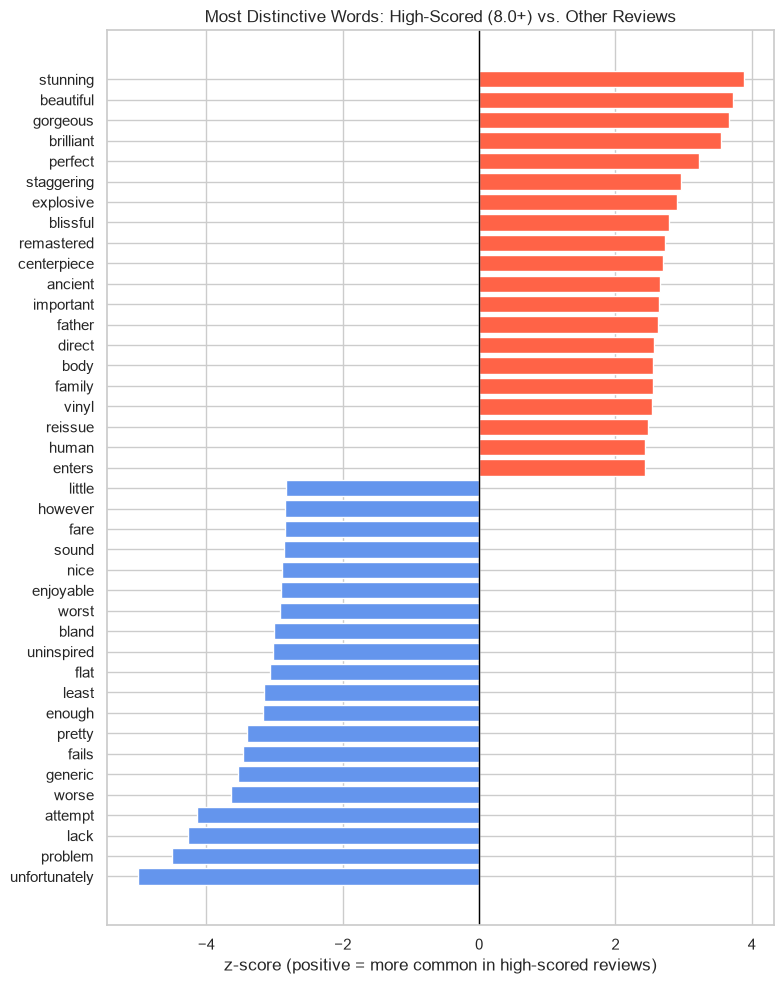

In [55]:
top_words = pd.concat([high_words.head(20), high_words.tail(20)])

plt.figure(figsize=(8, 10))

colors = [
    'tomato' if value > 0 else 'cornflowerblue'
    for value in top_words['z']
]

plt.barh(top_words['word'], top_words['z'], color = colors)
plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('z-score (positive = more common in high-scored reviews)')
plt.title('Most Distinctive Words: High-Scored (8.0+) vs. Other Reviews')

plt.tight_layout()
plt.show()

### Within genre

Genre is a confounder here: it drives both vocabulary ("rapper", "riff") and scores (Experimental and Jazz get more 8.0+ scores than Rock and Pop/R&B). So we also run the comparison separately inside each of the 5 biggest genres.

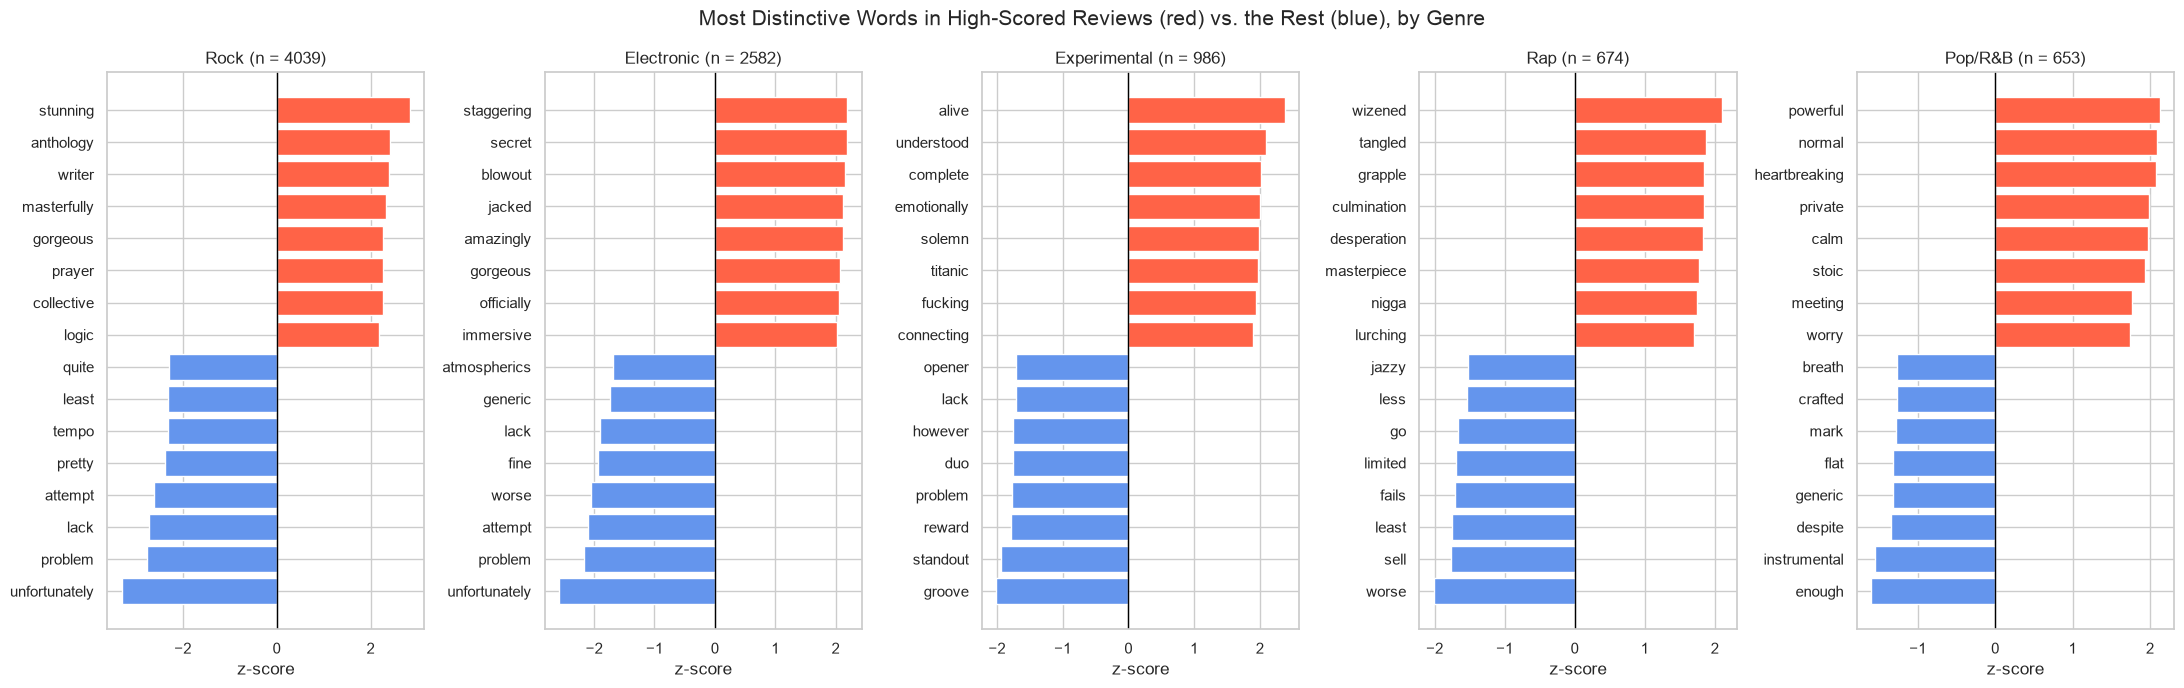

In [56]:
top_genres = review_df['genre'].value_counts().head(5).index

fig, axes = plt.subplots(1, 5, figsize=(22, 7))

for ax, genre in zip(axes, top_genres):
    in_genre = (review_df['genre'] == genre).values
    result = log_odds(counts[in_genre], review_df['high'].values[in_genre], vocab)
    top = pd.concat([result.head(8), result.tail(8)])

    colors = [
        'tomato' if value > 0 else 'cornflowerblue'
        for value in top['z']
    ]

    ax.barh(top['word'], top['z'], color = colors)
    ax.axvline(0, color = 'black', linewidth = 1)
    ax.set_title(f"{genre} (n = {in_genre.sum()})")
    ax.set_xlabel('z-score')

fig.suptitle('Most Distinctive Words in High-Scored Reviews (red) vs. the Rest (blue), by Genre', fontsize = 15)
plt.tight_layout()
plt.show()

# 2. Topic Modeling (LDA)

LDA treats each review as a mix of topics, and each topic as a mix of words. It works on raw word counts (not TF-IDF).
- `min_df = 20`: drop words in fewer than 20 reviews (typos, rare names)
- `max_df = 0.3`: drop words in more than 30% of reviews. Words like "good", "little", "never" otherwise show up in every topic and blur them together.

How we picked the settings:
- We tried 10, 12, 15, and 20 topics, and `max_df` of 0.5, 0.3, and 0.2.
- With 15+ topics, LDA kept making 1-2 tiny "leftover" topics (under 1% of the text, made of odd names). 12 topics with `max_df = 0.3` gave a set where every topic is real and readable.
- LDA depends on its random starting point, so we also refit with several seeds. The topics move around a bit, but the main high-vs-rest results below came out the same every time: emotional/lyrical writing and texture/composition go with high scores, casual "it's pretty good, I guess" writing goes with the rest.

In [57]:
lda_vec = CountVectorizer(min_df = 20, max_df = 0.3)
X = lda_vec.fit_transform(review_df['clean_text'])
lda_vocab = lda_vec.get_feature_names_out()

X.shape

(10758, 14107)

In [58]:
N_TOPICS = 12

lda = LatentDirichletAllocation(
    n_components = N_TOPICS,
    learning_method = 'batch',
    max_iter = 25,
    random_state = 1,
    n_jobs = -1
)

doc_topics = lda.fit_transform(X)

In [59]:
def show_topics(model, vocab, n_words = 12):
    for i, weights in enumerate(model.components_):
        top = vocab[weights.argsort()[::-1][:n_words]]
        print(f"Topic {i:>2}: {', '.join(top)}")

show_topics(lda, lda_vocab)

Topic  0: rap, hop, hip, rapper, producer, production, sample, verse, soul, guest, flow, style
Topic  1: folk, group, string, acoustic, organ, instrumental, percussion, harmony, psych, piano, however, member
Topic  2: indie, group, fan, career, production, early, better, material, decade, past, hit, least
Topic  3: punk, people, man, fuck, see, post, think, show, art, nothing, word, shit
Topic  4: recording, live, set, artist, version, recorded, jazz, musician, piece, solo, cover, musical
Topic  5: sings, word, singer, emotional, feeling, story, heart, relationship, light, death, past, personal
Topic  6: piece, piano, string, tone, drone, instrument, note, noise, bit, chord, acoustic, space
Topic  7: metal, black, riff, death, drummer, guitarist, heavy, punk, bass, noise, hardcore, post
Topic  8: electronic, synth, techno, noise, machine, ambient, space, synths, label, synthesizer, house, artist
Topic  9: dance, bass, house, mix, funk, producer, disco, synth, rhythm, style, groove, gen

In [60]:
# albums whose reviews are most "about" each topic
for i in range(N_TOPICS):
    top_docs = doc_topics[:, i].argsort()[::-1][:4]
    albums = review_df.iloc[top_docs]
    print(f"Topic {i:>2}:", '; '.join(albums['artist'] + ' - ' + albums['album']))

Topic  0: MC Eiht - Which Way Iz West; Scarface - The Fix; Lil Wayne - Sorry 4 the Wait; Nas - The Lost Tapes
Topic  1: Nick Castro and the Poison Tree - Further From Grace; James Blackshaw - O True Believers; AU - Verbs; The Music Tapes - Music Tapes for Clouds and Tornadoes
Topic  2: Wolf Parade - Expo 86; The Go! Team - The Scene Between; Doves - Lost Sides; Idaho - We Were Young and Needed the Money
Topic  3: Thursday - Full Collapse; Louis XIV - The Best Little Secrets Are Kept; Rob Swift - Wargames; Courtney Love - America's Sweetheart
Topic  4: The Source Family - The Source Family; John Coltrane - Blue World; Philip Glass - The Complete Sony Recordings; Fovea Hex - Allure EP
Topic  5: HTRK - Venus in Leo; Damien Jurado - In the Shape of a Storm; Frankie Cosmos - Close It Quietly; Molly Burch - First Flower
Topic  6: Chuck Johnson - Balsams; Hammock - Maybe They Will Sing for Us Tomorrow; James Blackshaw - The Glass Bead Game; Danny Paul Grody - Between Two Worlds
Topic  7: Mart

### Topic labels

Labels below are based on the top words and example albums above (for this run, `random_state = 1`). If you change the settings, the topics change and these need to be redone.

In [61]:
topic_labels = {
    0: 'Rap / hip-hop',
    1: 'Folk & psych instruments',
    2: 'Indie careers & production',
    3: 'Punk & attitude',
    4: 'Recordings, live & jazz',
    5: 'Lyrics & emotion',
    6: 'Composition & texture',
    7: 'Metal',
    8: 'Electronic & synths',
    9: 'Dance & funk',
    10: 'Casual critique',
    11: 'Country & folk singers'
}

topic_df = pd.DataFrame(
    doc_topics,
    columns = [topic_labels[i] for i in range(N_TOPICS)],
    index = review_df.index
)

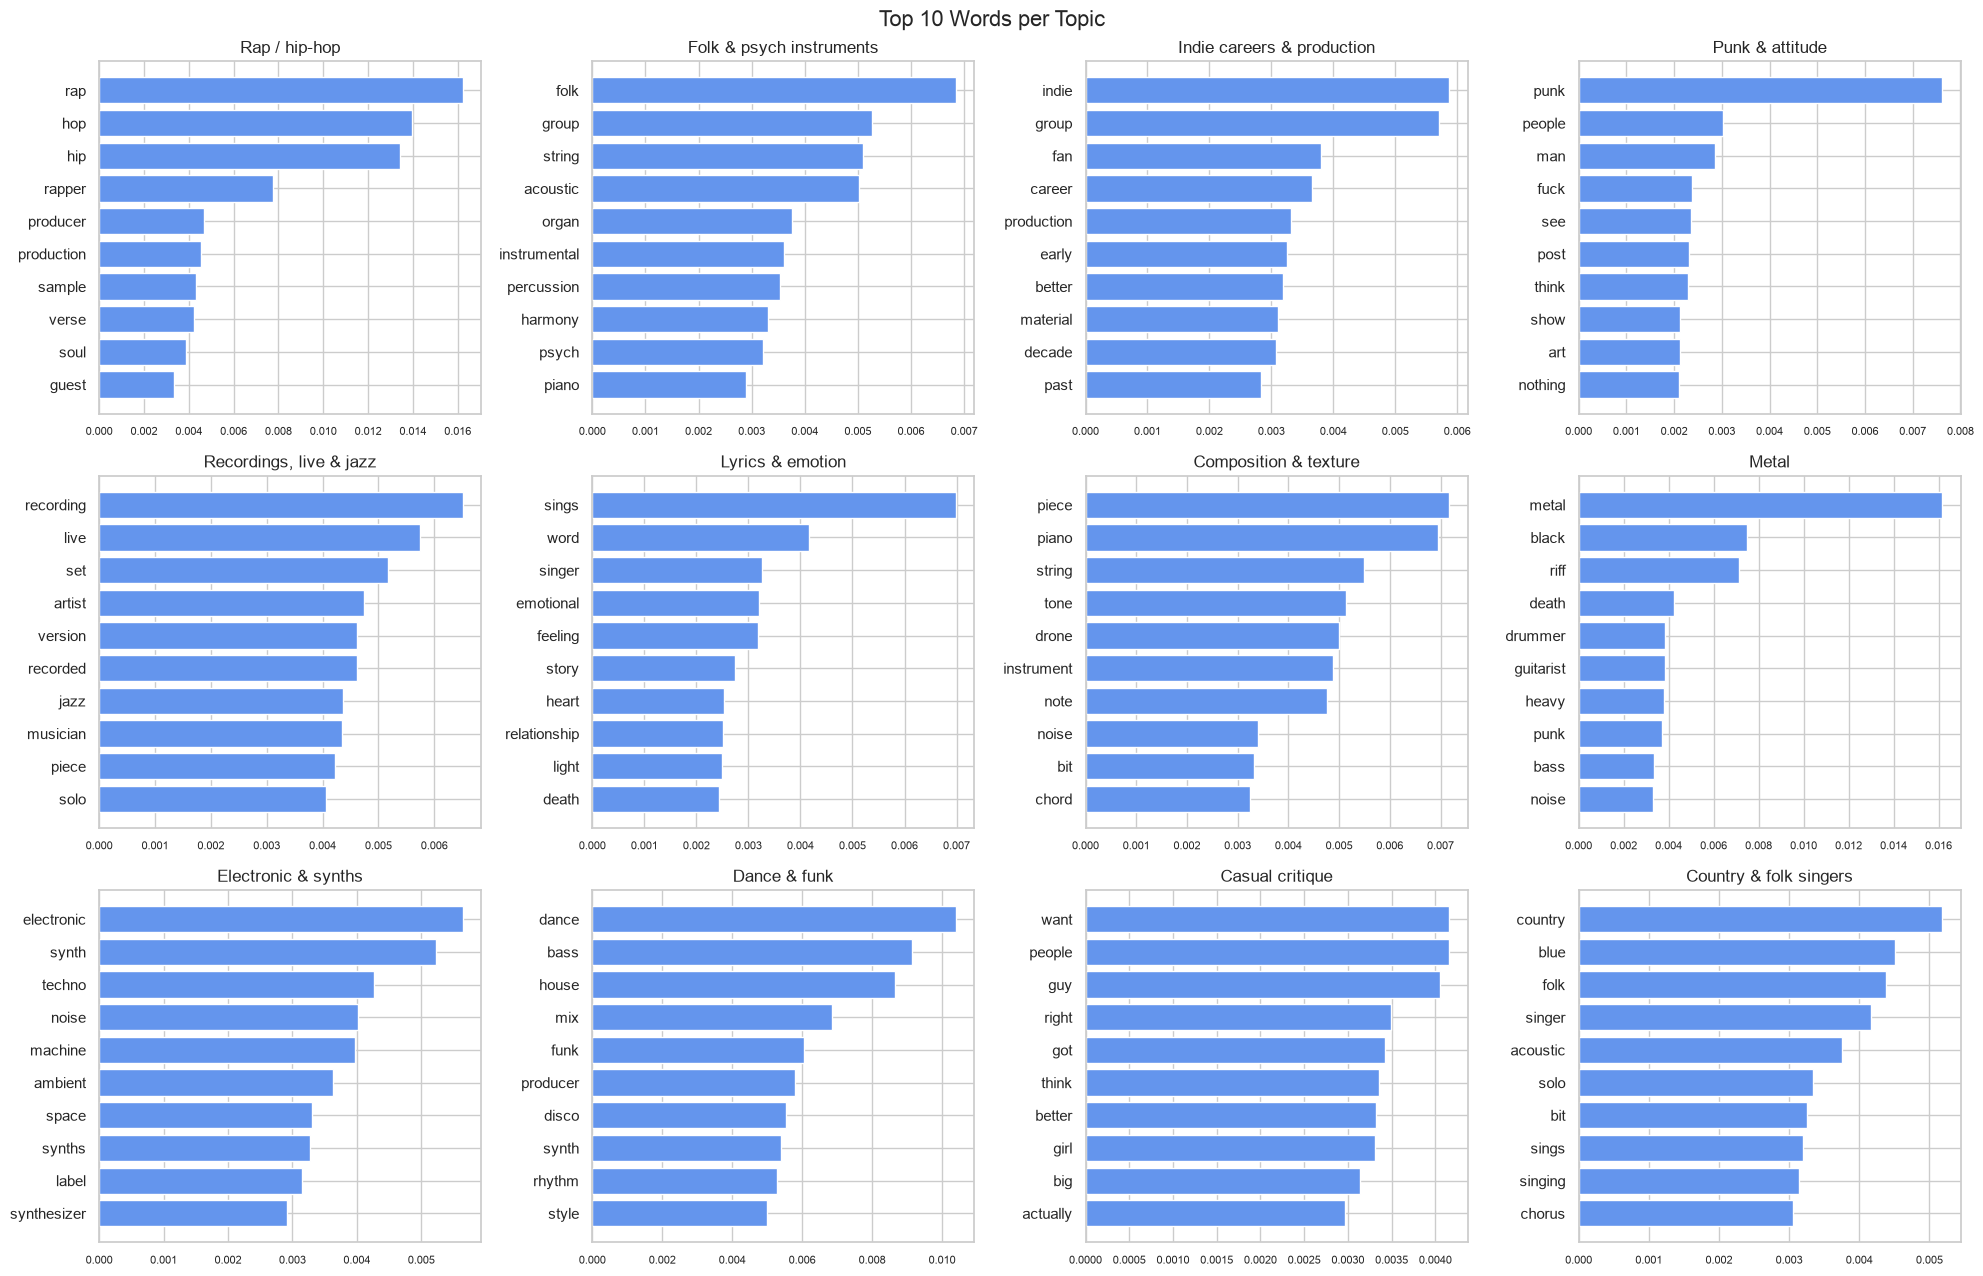

In [62]:
fig, axes = plt.subplots(3, 4, figsize=(20, 13))

for i, ax in enumerate(axes.flatten()):
    weights = lda.components_[i] / lda.components_[i].sum()
    top = weights.argsort()[::-1][:10]

    ax.barh(lda_vocab[top][::-1], weights[top][::-1], color = 'cornflowerblue')
    ax.set_title(topic_labels[i], fontsize = 12)
    ax.tick_params(axis = 'x', labelsize = 8)

fig.suptitle('Top 10 Words per Topic', fontsize = 16)
plt.tight_layout()
plt.show()

### Topic share: high vs. rest

Average share of each topic in high-scored reviews minus the rest. Error bars are 95% confidence intervals.

In [63]:
is_high = review_df['high'].values

topic_by_high = pd.DataFrame({
    'rest': topic_df[~is_high].mean(),
    'high': topic_df[is_high].mean()
})
topic_by_high['diff'] = topic_by_high['high'] - topic_by_high['rest']
topic_by_high['se'] = np.sqrt(
    topic_df[is_high].var() / is_high.sum()
    + topic_df[~is_high].var() / (~is_high).sum()
)
topic_by_high = topic_by_high.sort_values('diff')

topic_by_high.round(3)

,rest,high,diff,se
Indie careers & production,0.112,0.069,-0.043,0.003
Casual critique,0.117,0.085,-0.032,0.003
Country & folk singers,0.098,0.075,-0.022,0.003
Dance & funk,0.075,0.069,-0.007,0.003
Folk & psych instruments,0.049,0.050,0.001,0.002
Electronic & synths,0.089,0.092,0.002,0.003
Rap / hip-hop,0.052,0.055,0.004,0.003
Punk & attitude,0.086,0.093,0.008,0.003
Metal,0.079,0.090,0.011,0.004
Composition & texture,0.077,0.093,0.016,0.003


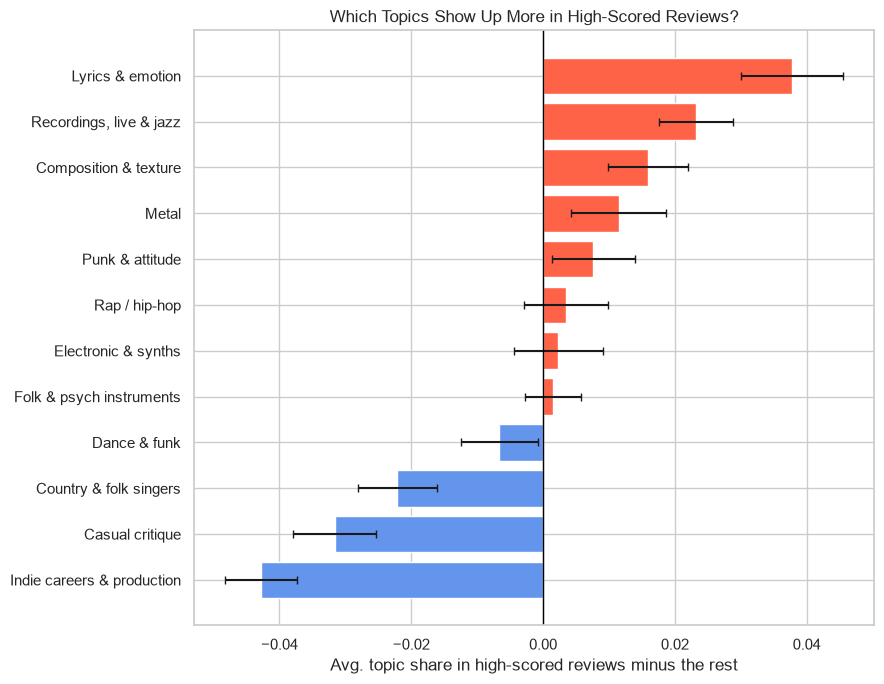

In [64]:
plt.figure(figsize=(9, 7))

colors = [
    'tomato' if value > 0 else 'cornflowerblue'
    for value in topic_by_high['diff']
]

plt.barh(
    topic_by_high.index,
    topic_by_high['diff'],
    xerr = 1.96 * topic_by_high['se'],
    color = colors,
    capsize = 3
)
plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('Avg. topic share in high-scored reviews minus the rest')
plt.title('Which Topics Show Up More in High-Scored Reviews?')

plt.tight_layout()
plt.show()

### Topics by genre

Which topics are just "genre topics" (e.g. metal, rap) and which cut across genres?

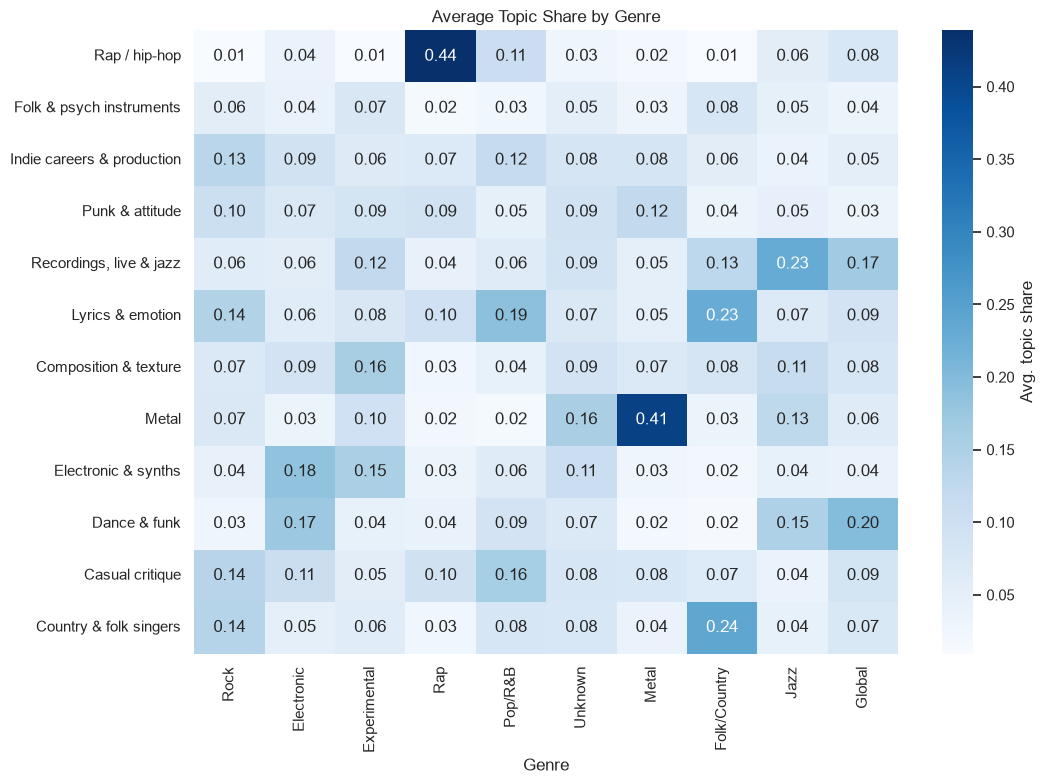

In [65]:
topic_by_genre = topic_df.groupby(review_df['genre']).mean().T

plt.figure(figsize=(11, 8))
sns.heatmap(
    topic_by_genre[review_df['genre'].value_counts().index],
    cmap = 'Blues',
    annot = True,
    fmt = '.2f',
    cbar_kws = {'label': 'Avg. topic share'}
)
plt.title('Average Topic Share by Genre')
plt.xlabel('Genre')
plt.ylabel('')

plt.tight_layout()
plt.show()

### High vs. rest, within genre

Same comparison as above, but inside each genre, so a topic doesn't look "high" just because it's common in a genre that gets high scores.

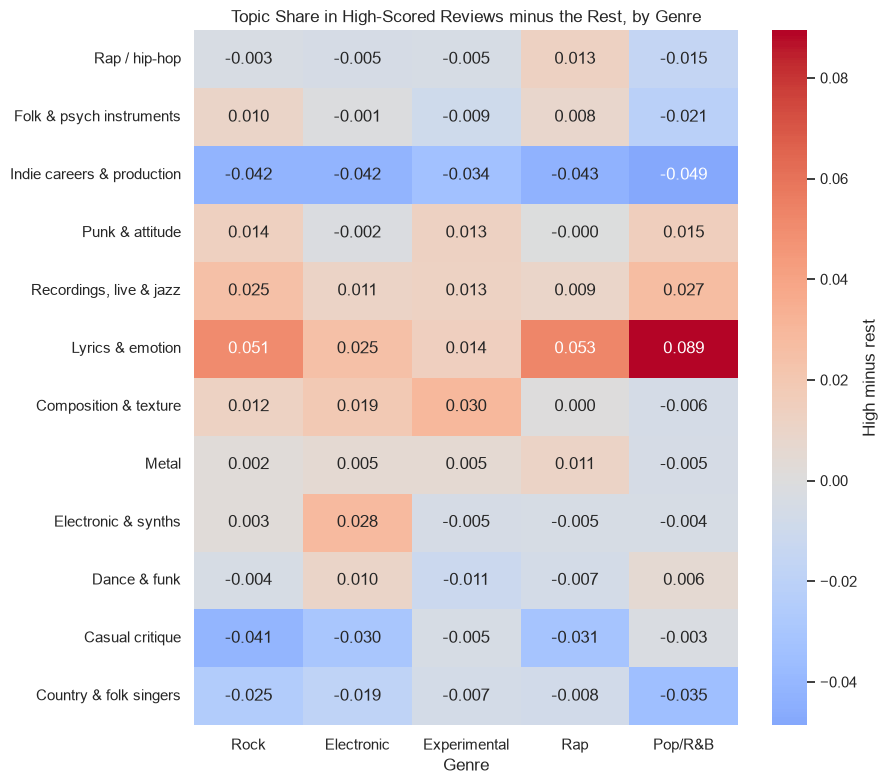

In [66]:
topic_by_genre_high = topic_df.groupby([review_df['genre'], review_df['high']]).mean()

within_genre_diff = (
    topic_by_genre_high.xs(True, level = 'high')
    - topic_by_genre_high.xs(False, level = 'high')
)

plt.figure(figsize=(9, 8))
sns.heatmap(
    within_genre_diff.loc[top_genres].T,
    cmap = 'coolwarm',
    center = 0,
    annot = True,
    fmt = '.3f',
    cbar_kws = {'label': 'High minus rest'}
)
plt.title('Topic Share in High-Scored Reviews minus the Rest, by Genre')
plt.xlabel('Genre')
plt.ylabel('')

plt.tight_layout()
plt.show()

### Save topic shares (for the regression later)

In [67]:
topic_out = pd.concat([review_df[['artist', 'album', 'reviewdate', 'score', 'genre', 'reviewauthor']], topic_df], axis = 1)
topic_out.to_csv("review_topics.csv", index = False)
topic_out.shape

(10758, 18)